## Pandas analysis

This exercise consists in analyzing a dataset containg timing information from a series of Time-to-Digital-Converters (TDC) implemented in a couple of FPGAs. Each measurement (i.e. each row of the input file) consists of a flag that specifies the type of message ('HEAD', which in this case is always 1), two addresses of the TDC providing the signal ('FPGA' and 'TDC_CHANNEL'), and the timing information ('ORBIT_CNT', 'BX_COUNTER', and 'TDC_MEAS'). Each TDC count corresponds to 25/30 ns, whereas a unit of BX_COUNTER corresponds to 25 ns, and the ORBIT_CNT is increased every 'x' BX_COUNTER. This allows to store the time in a similar way to hours, minutes and seconds.

In [1]:
import pandas as pd
import random as random

In [1]:
# If you didn't download it yet, please get the relevant file now!
!wget https://www.dropbox.com/s/xvjzaxzz3ysphme/data_000637.txt -P ~/data/

--2026-11-19 08:36:43--  https://www.dropbox.com/s/xvjzaxzz3ysphme/data_000637.txt
Resolving www.dropbox.com (www.dropbox.com)... 162.125.69.18, 2620:100:6025:18::a27d:4512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.69.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.dropbox.com/scl/fi/pkkpoxlm7beasryexpdf8/data_000637.txt?rlkey=rkm2em1v57hewglzelmin21c9 [following]
--2026-11-19 08:36:43--  https://www.dropbox.com/scl/fi/pkkpoxlm7beasryexpdf8/data_000637.txt?rlkey=rkm2em1v57hewglzelmin21c9
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://uc398e270129a7e03ecba8262fec.dl.dropboxusercontent.com/cd/0/inline/DMPgFfIH7jpN6hRcISbN2s7RpDzXPLM7U0y-cRTSd3BFWZfLagCfw_HLVHOTWF8Bwtm4tv4Aw15bfaQkDXEHh8fefDqkyJ4e-DrWZoT2hG0ShIVTxCHwrZqLha7LZNNrwrA/file# [following]
--2026-11-19 08:36:44--  https://uc398e270129a7e03ecba8262fec.dl.dropboxusercontent.com/cd/0/inline/DMPgFfIH7j

1\. Create a Pandas DataFrame reading N rows of the 'data_000637.txt' dataset. Choose N to be smaller than or equal to the maximum number of rows and larger that 10k.

2\. Find out the number of BX in a ORBIT (the value 'x').

3\. Find out how much the data taking lasted. You can either make an estimate based on the fraction of the measurements (rows) you read, or perform this check precisely by reading out the whole dataset.

4\. Create a new column with the absolute time in ns (as a combination of the other three columns with timing information).

5\. Replace the values (all 1) of the HEAD column randomly with 0 or 1.

6\. Create a new DataFrame that contains only the rows with HEAD=1.

7\. Make two occupancy plots (one for each FPGA), i.e. plot the number of counts per TDC channel

8\. Use the groupby method to find out the noisy channels, i.e. the TDC channels with most counts (say the top 3)

9\. Count the number of unique orbits. Count the number of unique orbits with at least one measurement from TDC_CHANNEL=139

In [2]:
file_name = "data_000637.txt.1"
data = pd.read_csv(file_name)
data.head()
# ultimas tres columnas son medidas de horas minutos y segundos 5 aunque en realidad no lo son

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS
0,1,0,123,3869200167,2374,26
1,1,0,124,3869200167,2374,27
2,1,0,63,3869200167,2553,28
3,1,0,64,3869200167,2558,19
4,1,0,64,3869200167,2760,25


In [10]:
# 1. Create a Pandas DataFrame reading N rows of the data...
max_pdf = data.shape[0]
tenk = 10000
N = random.randint(tenk + 1, max_pdf)
N_data = data[:N]

In [13]:
# 2. Find out the number of BX in a ORBIT (the value 'x').
result = data["BX_COUNTER"].max()
x = int(result)
x

3563

In [16]:
# 3. Find out how much the data taking lasted. You can either make an estimate based on the fraction of
# the measurements (rows) you read, or perform this check precisely by reading out the whole dataset.

# primero calculamos el numero total de orbitas
total_orbits = data["ORBIT_CNT"].max() - data["ORBIT_CNT"].min() + 1

# y luego el tiempo total , donde x es el valor obtenido en el ejercicio anterior
total_time = total_orbits * x * 25e-9
print(total_time, "seconds")

0.9802703749999999 seconds


In [ ]:
# 4.  Create a new column with the absolute time in ns 
# (as a combination of the other three columns with timing information).

# en este caso este es el timepo absoluto
# t = ORBIT\_CNT * x * 25 + BX\_COUNTER * 25 + TDC\_MEAS * \frac{25}{30}
# y todo queda en nano segundos

data["TIME_NS"] = (data["ORBIT_CNT"] * x * 25
                   + data["BX_COUNTER"] * 25
                   + data["TDC_MEAS"] * (25/30))

data.head(10)

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS,TIME_NS
0,1,0,123,3869200167,2374,26,3.446490e+14
1,1,0,124,3869200167,2374,27,3.446490e+14
2,1,0,63,3869200167,2553,28,3.446490e+14
3,1,0,64,3869200167,2558,19,3.446490e+14
4,1,0,64,3869200167,2760,25,3.446490e+14
5,1,0,63,3869200167,2762,4,3.446490e+14
6,1,0,61,3869200167,2772,14,3.446490e+14
7,1,0,139,3869200167,2776,0,3.446490e+14
8,1,0,62,3869200167,2774,21,3.446490e+14
9,1,0,60,3869200167,2788,7,3.446490e+14


In [23]:
# 5. Replace the values (all 1) of the HEAD column randomly with 0 or 1.
data["HEAD"] = [random.randint(0,1) for i in range(len(data))]
data.head(15)

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS,TIME_NS
0,1,0,123,3869200167,2374,26,3.446490e+14
1,1,0,124,3869200167,2374,27,3.446490e+14
2,0,0,63,3869200167,2553,28,3.446490e+14
3,0,0,64,3869200167,2558,19,3.446490e+14
4,0,0,64,3869200167,2760,25,3.446490e+14
5,1,0,63,3869200167,2762,4,3.446490e+14
6,0,0,61,3869200167,2772,14,3.446490e+14
7,0,0,139,3869200167,2776,0,3.446490e+14
8,0,0,62,3869200167,2774,21,3.446490e+14
9,0,0,60,3869200167,2788,7,3.446490e+14


In [ ]:
# 6. Create a new DataFrame that contains only the rows with HEAD=1.
data_head = data[data["HEAD"] == 1]
data_head.head(10)

,HEAD,FPGA,TDC_CHANNEL,ORBIT_CNT,BX_COUNTER,TDC_MEAS,TIME_NS
0,1,0,123,3869200167,2374,26,3.446490e+14
1,1,0,124,3869200167,2374,27,3.446490e+14
5,1,0,63,3869200167,2762,4,3.446490e+14
10,1,1,7,3869200167,2785,4,3.446490e+14
12,1,1,6,3869200167,2792,18,3.446490e+14
13,1,0,36,3869200167,2791,23,3.446490e+14
14,1,0,56,3869200167,2789,3,3.446490e+14
15,1,1,139,3869200167,2797,0,3.446490e+14
17,1,0,63,3869200167,2790,10,3.446490e+14
20,1,1,10,3869200167,2789,14,3.446490e+14


<Axes: xlabel='TDC_CHANNEL'>

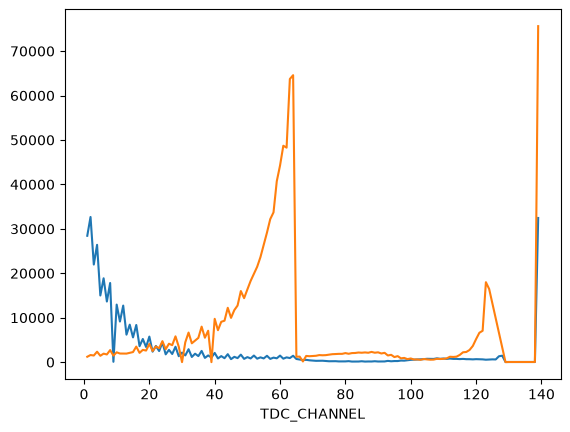

In [ ]:
# 7. Make two occupancy plots (one for each FPGA), i.e. plot the number of counts per TDC channel

# value_counts() cuenta las apariciones de cada canal
# sort_index() ordena los canales numéricamente

oness = data.loc[data["FPGA"] == 1]
oness["TDC_CHANNEL"].value_counts().sort_index().plot()

t= data.loc[data["FPGA"] == 0]
t["TDC_CHANNEL"].value_counts().sort_index().plot()

In [ ]:
# 8. Use the groupby method to find out the noisy channels, i.e. the TDC channels with most counts (say the top 3)

result = data.groupby("TDC_CHANNEL").size() # agrupamos por tdc chanel y contamos cuantas filas hay en cada grupo
# cuantas hay para tdc = 1, cuantas para TDC = 2 y asi
top_3 = result.sort_values(ascending=False).head(3) # sorteamos de mayor a menor y sacamos los 3 valores mas altos
# al poner ascending false empieza desde elmas alto al mas bajo
top_3

TDC_CHANNEL
139    108059
64      66020
63      64642
dtype: int64

In [32]:
# 9. Count the number of unique orbits. 
# Count the number of unique orbits with at least one measurement from TDC_CHANNEL=139
# result = pd.DataFrame(data.groupby('TDC_CHANNEL')["ORBIT_CNT"].nunique())
# result.loc[result["TDC_CHANNEL"] == 139, ["ORBIT_CNT"]]

# ocntamos el numero de orbitas unicas
result = data["ORBIT_CNT"].nunique()
print(result)

# aqui simplemente ubicamos donde TCD channel es 139 para orbits, y sacamos el numero de valroes unicos
result_139 = data.loc[data["TDC_CHANNEL"] == 139, "ORBIT_CNT"].nunique()
print(result_139)

11001
10976
